In [ ]:
import pandas as pd
import numpy as np

# So we are able to see all columns
pd.set_option('display.max_rows', 2000)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
files = os.listdir(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics"
)
files

['sampled_all_systems.csv',
 'concat_flaml.csv',
 'concat_ag.csv',
 'result_monotonic_llama.csv',
 'result_monotonic_mistral.csv',
 'llama.csv',
 'mistral.csv',
 'result_equal_monotonic_ag_equal.csv',
 'result_monotonic_ag_equal.csv',
 'result_equal_monotonic_flaml_equal.csv',
 'result_monotonic_flaml_equal.csv',
 'result_equal_monotonic_rf_equal.csv',
 'result_monotonic_rf_equal.csv',
 'old_concat_rf.csv',
 'old_hpo_all_systems.csv',
 'concat_rf.csv',
 'hpo_all_systems.csv']

In [ ]:
# This is to simply obtain the dataset's type (multi or bin)
dataset_and_type = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/results_100_stratified.csv",
    sep=";"
)
dataset_and_type = dataset_and_type.loc[:, ["dataset"]]
dataset_and_type = dataset_and_type.drop_duplicates(subset=["dataset"], ignore_index=True)
dataset_and_type["pure_dataset"] = dataset_and_type["dataset"].str[:5]
dataset_and_type

,dataset,pure_dataset
0,ed_01_multi,ed_01
1,ed_02_multi,ed_02
2,ed_03_multi,ed_03
3,ed_04_multi,ed_04
4,ed_05_multi,ed_05
5,fn_01_multi,fn_01
6,fn_02_bin,fn_02
7,fn_03_multi,fn_03
8,fn_04_multi,fn_04
9,fn_05_multi,fn_05


# AutoGluon

In [ ]:
system = "ag"
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

## HPO

In [ ]:
hpo = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)
hpo = hpo[hpo["automl_system"] == system_map[system]]
hpo = hpo.merge(
    dataset_and_type,
    left_on="trained_dataset",
    right_on="pure_dataset",
)
hpo = hpo.rename(
    columns={
        "trained_dataset": "pure_trained_dataset",
        "dataset": "trained_dataset",
    }
)
hpo = hpo.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
hpo = hpo.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)
hpo = hpo.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
hpo["predicted_type"] = "bin"
multi_mask = hpo["predicted_dataset"].str.contains("multi")
hpo.loc[multi_mask, "predicted_type"] = "multi"

hpo["are_concat_pred_equal"] = hpo.apply(
    lambda row: row["trained_dataset"] == row["predicted_dataset"],
    axis=1
)
equal_hpo = hpo[hpo["are_concat_pred_equal"]]
diff_hpo = hpo[~(hpo["are_concat_pred_equal"])]
hpo

,pure_trained_dataset,pure_predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,are_concat_pred_equal
0,fn_02,fn_06,AutoGluon,gmm_random,100,[],[],False,0.535865,0.502110,"['false', 'true']","['false', 'true']",fn_02_bin,fn_02,fn_06_bin,fn_06,fn,bin,False
1,fn_02,fn_02,AutoGluon,gmm_random,100,[],[],False,0.520833,0.500000,"['false', 'true']","['false', 'true']",fn_02_bin,fn_02,fn_02_bin,fn_02,fn,bin,True
2,hs_09,hs_03,AutoGluon,gmm_random,100,['hate'],[],True,0.502101,0.497899,"['hate', 'not_hate']",['not_hate'],hs_09_bin,hs_09,hs_03_bin,hs_03,hs,bin,False
3,hs_09,hs_06,AutoGluon,gmm_random,100,['hate'],[],True,0.577408,0.577408,"['hate', 'not_hate']",['not_hate'],hs_09_bin,hs_09,hs_06_bin,hs_06,hs,bin,False
4,hs_09,hs_08,AutoGluon,gmm_random,100,['hate'],[],True,0.930996,0.930996,"['hate', 'not_hate']",['not_hate'],hs_09_bin,hs_09,hs_08_bin,hs_08,hs,bin,False
5,hs_09,hs_10,AutoGluon,gmm_random,100,['hate'],[],True,0.550000,0.550000,"['hate', 'not_hate']",['not_hate'],hs_09_bin,hs_09,hs_10_bin,hs_10,hs,bin,False
6,hs_09,hs_12,AutoGluon,gmm_random,100,['hate'],[],True,0.554054,0.445946,"['hate', 'not_hate']",['not_hate'],hs_09_bin,hs_09,hs_12_bin,hs_12,hs,bin,False
7,hs_09,hs_09,AutoGluon,gmm_random,100,[],[],False,0.951535,0.949919,"['hate', 'not_hate']","['hate', 'not_hate']",hs_09_bin,hs_09,hs_09_bin,hs_09,hs,bin,True
8,hs_10,hs_03,AutoGluon,gmm_random,100,[],[],False,0.502101,0.665966,"['hate', 'not_hate']","['hate', 'not_hate']",hs_10_bin,hs_10,hs_03_bin,hs_03,hs,bin,False
9,hs_10,hs_06,AutoGluon,gmm_random,100,[],[],False,0.577408,0.607665,"['hate', 'not_hate']","['hate', 'not_hate']",hs_10_bin,hs_10,hs_06_bin,hs_06,hs,bin,False


## Concat

In [ ]:
automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_{system}.csv",
    sep=";"
)
automl_concat_df = automl_concat_df.merge(
    dataset_and_type,
    left_on="trained_dataset",
    right_on="pure_dataset",
)
automl_concat_df = automl_concat_df.rename(
    columns={
        "trained_dataset": "pure_trained_dataset",
        "dataset": "trained_dataset",
    }
)
automl_concat_df = automl_concat_df.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
automl_concat_df = automl_concat_df.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)

automl_concat_df = automl_concat_df.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
automl_concat_df["predicted_type"] = "bin"
multi_mask = automl_concat_df["predicted_dataset"].str.contains("multi")
automl_concat_df.loc[multi_mask, "predicted_type"] = "multi"

automl_concat_df["trained_type"] = "bin"
multi_mask = automl_concat_df["trained_dataset"].str.contains("multi")
automl_concat_df.loc[multi_mask, "trained_type"] = "multi"

adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["pure_predicted_dataset"]
aug_mask = automl_concat_df["pure_trained_dataset"] == automl_concat_df["pure_predicted_dataset"]

equal_concat_df = automl_concat_df.loc[adapt_mask & (~aug_mask)]
diff_concat_df = automl_concat_df.loc[(~adapt_mask) & (~aug_mask)]

automl_concat_df

,pure_trained_dataset,pure_predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,trained_type
0,ed_03,ed_01,ed_01,AutoGluon,gmm_random,25,"['surprise', 'disgust', 'anger']","['admiration', 'disappointment', 'neutral', 'g...",False,0.307054,0.132780,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['admiration', 'sadness', 'joy', 'disappointme...",ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
1,ed_03,ed_02,ed_01,AutoGluon,gmm_random,25,[],"['curiosity', 'nervousness', 'embarrassment', ...",False,0.342871,0.107823,"['sadness', 'joy', 'surprise', 'fear', 'love',...","['sadness', 'embarrassment', 'excitement', 'an...",ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
2,ed_03,ed_03,ed_01,AutoGluon,gmm_random,25,['relief'],[],False,0.294867,0.467042,"['sadness', 'embarrassment', 'excitement', 'an...","['sadness', 'embarrassment', 'excitement', 'an...",ed_03_multi,ed_03,ed_03_multi,ed_03,ed,multi,multi
3,ed_03,ed_01,ed_01,AutoGluon,gmm_random,50,['anger'],"['curiosity', 'admiration', 'remorse', 'neutral']",False,0.307054,0.302905,"['sadness', 'joy', 'surprise', 'fear', 'anger'...","['curiosity', 'admiration', 'sadness', 'joy', ...",ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
4,ed_03,ed_02,ed_01,AutoGluon,gmm_random,50,[],"['curiosity', 'nervousness', 'embarrassment', ...",False,0.342871,0.147415,"['sadness', 'joy', 'surprise', 'fear', 'love',...","['sadness', 'embarrassment', 'excitement', 'an...",ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2035,ua_06,ua_01,ua_05,AutoGluon,gmm_random,75,[],[],False,0.558380,0.577014,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']",ua_06_multi,ua_06,ua_01_multi,ua_01,ua,multi,multi
2036,ua_06,ua_03,ua_05,AutoGluon,gmm_random,75,['5'],[],False,0.666016,0.667317,"['3', '5', '10', '1', '7']","['3', '7', '10', '1']",ua_06_multi,ua_06,ua_03_multi,ua_03,ua,multi,multi
2037,ua_06,ua_04,ua_05,AutoGluon,gmm_random,75,[],[],False,0.200040,0.261252,"['3', '5', '10', '1', '7']","['3', '5', '10', '1', '7']",ua_06_multi,ua_06,ua_04_multi,ua_04,ua,multi,multi
2038,ua_06,ua_05,ua_05,AutoGluon,gmm_random,75,"['5', '7']",[],False,0.776119,0.798507,"['3', '5', '10', '1', '7']","['3', '10', '1']",ua_06_multi,ua_06,ua_05_multi,ua_05,ua,multi,multi


## 1. Evaluating Concat Equal

### 1.1 Frequency based on hold_out_f1_score

#### 1.1.1 System/Task/Percentage


In [ ]:
equal_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
AutoGluon      ed              25            0.400274
                               50            0.470764
                               75            0.501581
               fn              25            0.463772
                               50            0.466124
                               75            0.517341
               hs              25            0.727658
                               50            0.744722
                               75            0.761362
               pc              25            0.787452
                               50            0.795352
                               75            0.794351
               sd              25            0.388000
                               50            0.450667
                               75            0.498667
               ua              25            0.624109
                               50            0.628726
                               75            0.635263
Name: hold_out_f1_score, dtype: float64

#### 1.1.2 System/Task/Percentage/Type


In [ ]:
equal_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
AutoGluon      ed              25          multi             0.400274
                               50          multi             0.470764
                               75          multi             0.501581
               fn              25          bin               0.473743
                                           multi             0.438846
                               50          bin               0.475879
                                           multi             0.441737
                               75          bin               0.535469
                                           multi             0.472020
               hs              25          bin               0.742634
                                           multi             0.657768
                               50          bin               0.759467
                                           multi             0.675908
                               75          bin               0.770372
                                           multi             0.719316
               pc              25          bin               0.826272
                                           multi             0.614922
                               50          bin               0.832686
                                           multi             0.629423
                               75          bin               0.829734
                                           multi             0.637091
               sd              25          multi             0.388000
                               50          multi             0.450667
                               75          multi             0.498667
               ua              25          multi             0.624109
                               50          multi             0.628726
                               75          multi             0.635263
Name: hold_out_f1_score, dtype: float64

#### 1.1.3 System/Percentage/Type

In [ ]:
equal_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
AutoGluon      25          bin               0.751052
                           multi             0.591991
               50          bin               0.760658
                           multi             0.605171
               75          bin               0.770698
                           multi             0.621247
Name: hold_out_f1_score, dtype: float64

#### 1.1.4 Task/Percentage

In [ ]:
equal_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  percentage
ed              25            0.400274
                50            0.470764
                75            0.501581
fn              25            0.463772
                50            0.466124
                75            0.517341
hs              25            0.727658
                50            0.744722
                75            0.761362
pc              25            0.787452
                50            0.795352
                75            0.794351
sd              25            0.388000
                50            0.450667
                75            0.498667
ua              25            0.624109
                50            0.628726
                75            0.635263
Name: hold_out_f1_score, dtype: float64

#### 1.1.5 Percentage/Task/Type

In [ ]:
equal_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           25            0.400274
                                50            0.470764
                                75            0.501581
fn              bin             25            0.473743
                                50            0.475879
                                75            0.535469
                multi           25            0.438846
                                50            0.441737
                                75            0.472020
hs              bin             25            0.742634
                                50            0.759467
                                75            0.770372
                multi           25            0.657768
                                50            0.675908
                                75            0.719316
pc              bin             25            0.826272
                                50            0.832686
                                75            0.829734
                multi           25            0.614922
                                50            0.629423
                                75            0.637091
sd              multi           25            0.388000
                                50            0.450667
                                75            0.498667
ua              multi           25            0.624109
                                50            0.628726
                                75            0.635263
Name: hold_out_f1_score, dtype: float64

#### 1.1.6 Type

In [ ]:
equal_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.760803
multi,0.606136


#### 1.1.7 Percentage/Type

In [ ]:
equal_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_type  percentage
bin             25            0.751052
                50            0.760658
                75            0.770698
multi           25            0.591991
                50            0.605171
                75            0.621247
Name: hold_out_f1_score, dtype: float64

### 1.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    equal_concat_df
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        equal_concat_df,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,AutoGluon,ed_01_multi,gmm_random,50,0.302905
1,AutoGluon,ed_02_multi,gmm_random,75,0.708556
2,AutoGluon,fn_02_bin,gmm_random,75,0.611111
3,AutoGluon,fn_05_multi,gmm_random,25,0.519545
4,AutoGluon,fn_06_bin,gmm_random,75,0.556962
5,AutoGluon,fn_07_multi,gmm_random,75,0.457386
6,AutoGluon,fn_09_multi,gmm_random,75,0.476111
7,AutoGluon,fn_10_multi,gmm_random,75,0.500000
8,AutoGluon,hs_01_bin,gmm_random,50,0.840607
9,AutoGluon,hs_02_multi,gmm_random,75,0.858782


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        equal_concat_df
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            equal_concat_df,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
1,AutoGluon,ed_01_multi,gmm_random,50,0.302905,True
3,AutoGluon,ed_02_multi,gmm_random,25,0.667767,False
18,AutoGluon,fn_02_bin,gmm_random,25,0.527778,False
21,AutoGluon,fn_05_multi,gmm_random,25,0.519545,False
28,AutoGluon,fn_06_bin,gmm_random,50,0.535865,True
40,AutoGluon,fn_07_multi,gmm_random,50,0.423295,True
43,AutoGluon,fn_09_multi,gmm_random,50,0.435876,True
46,AutoGluon,fn_10_multi,gmm_random,50,0.466667,True
49,AutoGluon,hs_01_bin,gmm_random,50,0.840607,True
58,AutoGluon,hs_02_multi,gmm_random,50,0.847712,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,ed_02_multi,gmm_random,25,0.667767,False
1,AutoGluon,fn_02_bin,gmm_random,25,0.527778,False
2,AutoGluon,fn_05_multi,gmm_random,25,0.519545,False
3,AutoGluon,hs_03_bin,gmm_random,25,0.760504,False
4,AutoGluon,hs_06_bin,gmm_random,25,0.613464,False
5,AutoGluon,hs_09_bin,gmm_random,25,0.949919,False
6,AutoGluon,hs_10_bin,gmm_random,25,0.720000,False
7,AutoGluon,hs_14_bin,gmm_random,25,0.653509,False
8,AutoGluon,pc_04_bin,gmm_random,25,0.898184,False
9,AutoGluon,pc_05_multi,gmm_random,25,0.573541,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,ed_02_multi,gmm_random,25,0.667767,False
1,AutoGluon,fn_02_bin,gmm_random,25,0.527778,False
2,AutoGluon,fn_05_multi,gmm_random,25,0.519545,False
3,AutoGluon,hs_03_bin,gmm_random,25,0.760504,False
4,AutoGluon,hs_06_bin,gmm_random,25,0.613464,False
5,AutoGluon,hs_09_bin,gmm_random,25,0.949919,False
6,AutoGluon,hs_10_bin,gmm_random,25,0.720000,False
7,AutoGluon,hs_14_bin,gmm_random,25,0.653509,False
8,AutoGluon,pc_04_bin,gmm_random,25,0.898184,False
9,AutoGluon,pc_05_multi,gmm_random,25,0.573541,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,ed_02_multi,gmm_random,25,0.667767,False
1,AutoGluon,fn_02_bin,gmm_random,25,0.527778,False
2,AutoGluon,fn_05_multi,gmm_random,25,0.519545,False
3,AutoGluon,hs_03_bin,gmm_random,25,0.760504,False
4,AutoGluon,hs_06_bin,gmm_random,25,0.613464,False
5,AutoGluon,hs_09_bin,gmm_random,25,0.949919,False
6,AutoGluon,hs_10_bin,gmm_random,25,0.720000,False
7,AutoGluon,hs_14_bin,gmm_random,25,0.653509,False
8,AutoGluon,pc_04_bin,gmm_random,25,0.898184,False
9,AutoGluon,pc_05_multi,gmm_random,25,0.573541,False


### 1.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 1.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-3951610294.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.581006
"(0.05, 0.1]",0.727257
"(0.1, 0.2]",0.709894
"(0.2, 0.3]",0.766086
"(0.3, 0.5]",0.528279
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.444444
"(0.7, 0.8]",0.756714
"(0.8, 0.9]",0.575405


#### 1.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-1533895566.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.457540
               fn             0.494452
               hs             0.693703
               ua             0.606351
(0.05, 0.1]    hs             0.684331
               pc             0.759452
(0.1, 0.2]     hs             0.672515
               pc             0.777528
               ua             0.639933
(0.2, 0.3]     fn             0.440626
               hs             0.920838
               pc             0.790473
(0.3, 0.5]     fn             0.468511
               hs             0.767351
(0.6, 0.7]     sd             0.444444
(0.7, 0.8]     hs             0.756714
(0.8, 0.9]     fn             0.467593
               hs             0.811512
               sd             0.447111
(0.9, 1.0]     fn             0.502399
               hs             0.775860
               pc             0.816627
               ua             0.641055

## 2. Evaluating Concat Diff

### 2.1 Frequency based on hold_out_f1_score

#### 2.1.1 System/Task/Percentage


In [ ]:
diff_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
AutoGluon      ed              25            0.060135
                               50            0.084081
                               75            0.079647
               fn              25            0.410579
                               50            0.376571
                               75            0.438280
               hs              25            0.651198
                               50            0.649505
                               75            0.647872
               pc              25            0.644144
                               50            0.634194
                               75            0.643560
               ua              25            0.499937
                               50            0.504627
                               75            0.506408
Name: hold_out_f1_score, dtype: float64

#### 2.1.2 System/Task/Percentage/Type


In [ ]:
diff_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
AutoGluon      ed              25          multi             0.060135
                               50          multi             0.084081
                               75          multi             0.079647
               fn              25          bin               0.410579
                               50          bin               0.376571
                               75          bin               0.438280
               hs              25          bin               0.660642
                                           multi             0.434005
                               50          bin               0.659863
                                           multi             0.411277
                               75          bin               0.657004
                                           multi             0.437834
               pc              25          bin               0.705484
                                           multi             0.445056
                               50          bin               0.692785
                                           multi             0.444029
                               75          bin               0.707175
                                           multi             0.437091
               ua              25          multi             0.499937
                               50          multi             0.504627
                               75          multi             0.506408
Name: hold_out_f1_score, dtype: float64

#### 2.1.3 System/Percentage/Type

In [ ]:
diff_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
AutoGluon      25          bin               0.682730
                           multi             0.470066
               50          bin               0.673281
                           multi             0.471979
               75          bin               0.683432
                           multi             0.470891
Name: hold_out_f1_score, dtype: float64

#### 2.1.4 Task/Percentage

In [ ]:
diff_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  percentage
ed              25            0.060135
                50            0.084081
                75            0.079647
fn              25            0.410579
                50            0.376571
                75            0.438280
hs              25            0.651198
                50            0.649505
                75            0.647872
pc              25            0.644144
                50            0.634194
                75            0.643560
ua              25            0.499937
                50            0.504627
                75            0.506408
Name: hold_out_f1_score, dtype: float64

#### 2.1.5 Percentage/Task/Type

In [ ]:
diff_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           25            0.060135
                                50            0.084081
                                75            0.079647
fn              bin             25            0.410579
                                50            0.376571
                                75            0.438280
hs              bin             25            0.660642
                                50            0.659863
                                75            0.657004
                multi           25            0.434005
                                50            0.411277
                                75            0.437834
pc              bin             25            0.705484
                                50            0.692785
                                75            0.707175
                multi           25            0.445056
                                50            0.444029
                                75            0.437091
ua              multi           25            0.499937
                                50            0.504627
                                75            0.506408
Name: hold_out_f1_score, dtype: float64

#### 2.1.6 Type

In [ ]:
diff_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.679814
multi,0.470979


#### 2.1.7 Percentage/Type

In [ ]:
diff_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_type  percentage
bin             25            0.682730
                50            0.673281
                75            0.683432
multi           25            0.470066
                50            0.471979
                75            0.470891
Name: hold_out_f1_score, dtype: float64

### 2.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    diff_concat_df
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        diff_concat_df,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,AutoGluon,ed_01_multi,gmm_random,75,0.037344
1,AutoGluon,ed_02_multi,gmm_random,50,0.147415
2,AutoGluon,fn_02_bin,gmm_random,25,0.520833
3,AutoGluon,fn_06_bin,gmm_random,50,0.540084
4,AutoGluon,hs_02_multi,gmm_random,25,0.727015
5,AutoGluon,hs_03_bin,gmm_random,50,0.691176
6,AutoGluon,hs_06_bin,gmm_random,25,0.618759
7,AutoGluon,hs_08_bin,gmm_random,25,0.930996
8,AutoGluon,hs_09_bin,gmm_random,25,0.917609
9,AutoGluon,hs_10_bin,gmm_random,50,0.736667


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        diff_concat_df
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            diff_concat_df,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
1,AutoGluon,ed_01_multi,gmm_random,50,0.020747,True
4,AutoGluon,ed_02_multi,gmm_random,50,0.147415,True
12,AutoGluon,fn_02_bin,gmm_random,25,0.520833,False
19,AutoGluon,fn_06_bin,gmm_random,50,0.540084,True
30,AutoGluon,hs_02_multi,gmm_random,25,0.727015,False
67,AutoGluon,hs_03_bin,gmm_random,50,0.691176,True
105,AutoGluon,hs_06_bin,gmm_random,25,0.618759,False
150,AutoGluon,hs_08_bin,gmm_random,25,0.930996,False
189,AutoGluon,hs_09_bin,gmm_random,25,0.917609,False
223,AutoGluon,hs_10_bin,gmm_random,50,0.736667,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,fn_02_bin,gmm_random,25,0.520833,False
1,AutoGluon,hs_02_multi,gmm_random,25,0.727015,False
2,AutoGluon,hs_06_bin,gmm_random,25,0.618759,False
3,AutoGluon,hs_08_bin,gmm_random,25,0.930996,False
4,AutoGluon,hs_09_bin,gmm_random,25,0.917609,False
5,AutoGluon,hs_12_bin,gmm_random,25,0.513514,False
6,AutoGluon,pc_02_bin,gmm_random,25,0.818697,False
7,AutoGluon,pc_03_bin,gmm_random,25,0.855242,False
8,AutoGluon,pc_05_multi,gmm_random,25,0.537241,False
9,AutoGluon,pc_07_multi,gmm_random,25,0.693416,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,fn_02_bin,gmm_random,25,0.520833,False
1,AutoGluon,hs_02_multi,gmm_random,25,0.727015,False
2,AutoGluon,hs_06_bin,gmm_random,25,0.618759,False
3,AutoGluon,hs_08_bin,gmm_random,25,0.930996,False
4,AutoGluon,hs_09_bin,gmm_random,25,0.917609,False
5,AutoGluon,hs_12_bin,gmm_random,25,0.513514,False
6,AutoGluon,pc_02_bin,gmm_random,25,0.818697,False
7,AutoGluon,pc_03_bin,gmm_random,25,0.855242,False
8,AutoGluon,pc_05_multi,gmm_random,25,0.537241,False
9,AutoGluon,pc_07_multi,gmm_random,25,0.693416,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,fn_02_bin,gmm_random,25,0.520833,False
1,AutoGluon,hs_02_multi,gmm_random,25,0.727015,False
2,AutoGluon,hs_06_bin,gmm_random,25,0.618759,False
3,AutoGluon,hs_08_bin,gmm_random,25,0.930996,False
4,AutoGluon,hs_09_bin,gmm_random,25,0.917609,False
5,AutoGluon,hs_12_bin,gmm_random,25,0.513514,False
6,AutoGluon,pc_02_bin,gmm_random,25,0.818697,False
7,AutoGluon,pc_03_bin,gmm_random,25,0.855242,False
8,AutoGluon,pc_05_multi,gmm_random,25,0.537241,False
9,AutoGluon,pc_07_multi,gmm_random,25,0.693416,False


### 2.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 2.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-3871234073.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.508926
"(0.05, 0.1]",0.546442
"(0.1, 0.2]",0.573435
"(0.2, 0.3]",0.629939
"(0.3, 0.5]",0.384655
"(0.5, 0.6]",NaN
"(0.6, 0.7]",NaN
"(0.7, 0.8]",0.671380
"(0.8, 0.9]",NaN


#### 2.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3687020511.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.074621
               fn             0.416418
               hs             0.618708
               ua             0.476761
(0.05, 0.1]    hs             0.427705
               pc             0.554923
(0.1, 0.2]     pc             0.603761
               ua             0.515539
(0.2, 0.3]     pc             0.629939
(0.3, 0.5]     fn             0.384655
(0.7, 0.8]     hs             0.671380
(0.9, 1.0]     hs             0.669632
               pc             0.779734
               ua             0.513883

## 3. Evaluating HPO Equal

### 3.1 Frequency based on hold_out_f1_score

#### 3.1.1 System/Task/Percentage


In [ ]:
equal_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
AutoGluon      ed              100           0.603052
               fn              100           0.502699
               hs              100           0.818478
               pc              100           0.747429
               sd              100           0.723209
               ua              100           0.580604
Name: hold_out_f1_score, dtype: float64

#### 3.1.2 System/Task/Percentage/Type


In [ ]:
equal_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
AutoGluon      ed              100         multi             0.603052
               fn              100         bin               0.479958
                                           multi             0.508384
               hs              100         bin               0.816734
                                           multi             0.823275
               pc              100         bin               0.812085
                                           multi             0.666610
               sd              100         bin               0.817708
                                           multi             0.691709
               ua              100         multi             0.580604
Name: hold_out_f1_score, dtype: float64

#### 3.1.3 System/Percentage/Type

In [ ]:
equal_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
AutoGluon      100         bin               0.780111
                           multi             0.620021
Name: hold_out_f1_score, dtype: float64

#### 3.1.4 Task/Percentage

In [ ]:
equal_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_task,percentage,
ed,100,0.603052
fn,100,0.502699
hs,100,0.818478
pc,100,0.747429
sd,100,0.723209
ua,100,0.580604


#### 3.1.5 Percentage/Task/Type

In [ ]:
equal_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           100           0.603052
fn              bin             100           0.479958
                multi           100           0.508384
hs              bin             100           0.816734
                multi           100           0.823275
pc              bin             100           0.812085
                multi           100           0.666610
sd              bin             100           0.817708
                multi           100           0.691709
ua              multi           100           0.580604
Name: hold_out_f1_score, dtype: float64

#### 3.1.6 Type

In [ ]:
equal_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.780111
multi,0.620021


#### 3.1.7 Percentage/Type

In [ ]:
equal_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_type,percentage,
bin,100,0.780111
multi,100,0.620021


### 3.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    equal_hpo
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        equal_hpo,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,AutoGluon,ed_01_multi,gmm_random,100,0.468880
1,AutoGluon,ed_02_multi,gmm_random,100,0.766363
2,AutoGluon,ed_03_multi,gmm_random,100,0.479597
3,AutoGluon,ed_04_multi,gmm_random,100,0.925421
4,AutoGluon,ed_05_multi,gmm_random,100,0.375000
5,AutoGluon,fn_01_multi,gmm_random,100,0.267238
6,AutoGluon,fn_02_bin,gmm_random,100,0.500000
7,AutoGluon,fn_03_multi,gmm_random,100,0.267678
8,AutoGluon,fn_04_multi,gmm_random,100,0.559633
9,AutoGluon,fn_05_multi,gmm_random,100,0.538171


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        equal_hpo
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            equal_hpo,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,ed_01_multi,gmm_random,100,0.468880,True
1,AutoGluon,ed_02_multi,gmm_random,100,0.766363,True
2,AutoGluon,ed_03_multi,gmm_random,100,0.479597,True
3,AutoGluon,ed_04_multi,gmm_random,100,0.925421,True
4,AutoGluon,ed_05_multi,gmm_random,100,0.375000,True
5,AutoGluon,fn_01_multi,gmm_random,100,0.267238,True
6,AutoGluon,fn_02_bin,gmm_random,100,0.500000,True
7,AutoGluon,fn_03_multi,gmm_random,100,0.267678,True
8,AutoGluon,fn_04_multi,gmm_random,100,0.559633,True
9,AutoGluon,fn_05_multi,gmm_random,100,0.538171,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


### 3.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 3.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-2734163324.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.702606
"(0.05, 0.1]",0.773631
"(0.1, 0.2]",0.589966
"(0.2, 0.3]",0.739533
"(0.3, 0.5]",0.581479
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.720854
"(0.7, 0.8]",0.641856
"(0.8, 0.9]",0.634476


#### 3.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3557226802.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.702509
               fn             0.556773
               hs             0.896444
               ua             0.727612
(0.05, 0.1]    ed             0.617621
               hs             0.851535
               pc             0.774038
(0.1, 0.2]     ed             0.375000
               hs             0.925574
               pc             0.659297
               ua             0.503532
(0.2, 0.3]     fn             0.583333
               hs             0.960526
               pc             0.573810
               sd             0.840461
(0.3, 0.5]     fn             0.425497
               hs             0.815453
(0.6, 0.7]     sd             0.720854
(0.7, 0.8]     hs             0.641856
(0.8, 0.9]     fn             0.459916
               hs             0.832845
               sd             0.610667
(0.9, 1.0]     fn             0.518466
               hs             0.722292
               pc             0.812085
               ua             0.517804

## 4. Evaluating HPO Diff

### 4.1 Frequency based on hold_out_f1_score

#### 4.1.1 System/Task/Percentage

In [ ]:
diff_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage
AutoGluon      ed              100           0.105626
               fn              100           0.355164
               hs              100           0.589015
               pc              100           0.559414
               sd              100           0.352000
               ua              100           0.521940
Name: hold_out_f1_score, dtype: float64

#### 4.1.2 System/Task/Percentage/Type


In [ ]:
diff_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  predicted_task  percentage  predicted_type
AutoGluon      ed              100         multi             0.105626
               fn              100         bin               0.353657
                                           multi             0.358933
               hs              100         bin               0.642235
                                           multi             0.340656
               pc              100         bin               0.584473
                                           multi             0.448042
               sd              100         multi             0.352000
               ua              100         multi             0.521940
Name: hold_out_f1_score, dtype: float64

#### 4.1.3 System/Percentage/Type

In [ ]:
diff_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system  percentage  predicted_type
AutoGluon      100         bin               0.575616
                           multi             0.442444
Name: hold_out_f1_score, dtype: float64

#### 4.1.4 Task/Percentage

In [ ]:
diff_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_task,percentage,
ed,100,0.105626
fn,100,0.355164
hs,100,0.589015
pc,100,0.559414
sd,100,0.352000
ua,100,0.521940


#### 4.1.5 Percentage/Task/Type

In [ ]:
diff_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           100           0.105626
fn              bin             100           0.353657
                multi           100           0.358933
hs              bin             100           0.642235
                multi           100           0.340656
pc              bin             100           0.584473
                multi           100           0.448042
sd              multi           100           0.352000
ua              multi           100           0.521940
Name: hold_out_f1_score, dtype: float64

#### 4.1.6 Type

In [ ]:
diff_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.575616
multi,0.442444


#### 4.1.7 Percentage/Type

In [ ]:
diff_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_type,percentage,
bin,100,0.575616
multi,100,0.442444


### 4.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    diff_hpo
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        diff_hpo,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,AutoGluon,ed_01_multi,gmm_random,100,0.020747
1,AutoGluon,ed_02_multi,gmm_random,100,0.190505
2,AutoGluon,fn_02_bin,gmm_random,100,0.520833
3,AutoGluon,fn_05_multi,gmm_random,100,0.388345
4,AutoGluon,fn_06_bin,gmm_random,100,0.502110
5,AutoGluon,fn_07_multi,gmm_random,100,0.394886
6,AutoGluon,fn_09_multi,gmm_random,100,0.285834
7,AutoGluon,fn_10_multi,gmm_random,100,0.366667
8,AutoGluon,hs_01_bin,gmm_random,100,0.450348
9,AutoGluon,hs_02_multi,gmm_random,100,0.711489


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        diff_hpo
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            diff_hpo,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,AutoGluon,ed_01_multi,gmm_random,100,0.020747,True
1,AutoGluon,ed_02_multi,gmm_random,100,0.190505,True
2,AutoGluon,fn_02_bin,gmm_random,100,0.520833,True
7,AutoGluon,fn_05_multi,gmm_random,100,0.388345,True
8,AutoGluon,fn_06_bin,gmm_random,100,0.502110,True
13,AutoGluon,fn_07_multi,gmm_random,100,0.394886,True
14,AutoGluon,fn_09_multi,gmm_random,100,0.285834,True
15,AutoGluon,fn_10_multi,gmm_random,100,0.366667,True
16,AutoGluon,hs_01_bin,gmm_random,100,0.450348,True
18,AutoGluon,hs_02_multi,gmm_random,100,0.711489,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


### 4.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 4.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-2727227245.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.430235
"(0.05, 0.1]",0.347045
"(0.1, 0.2]",0.500268
"(0.2, 0.3]",0.502077
"(0.3, 0.5]",0.340287
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.333333
"(0.7, 0.8]",0.676575
"(0.8, 0.9]",0.442653


#### 4.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-2953702698.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.105626
               fn             0.343296
               hs             0.600450
               ua             0.494191
(0.05, 0.1]    hs             0.340656
               pc             0.351837
(0.1, 0.2]     hs             0.574561
               pc             0.459358
               ua             0.538609
(0.2, 0.3]     fn             0.285834
               hs             0.830148
               pc             0.486102
(0.3, 0.5]     fn             0.307323
               hs             0.472141
(0.6, 0.7]     sd             0.333333
(0.7, 0.8]     hs             0.676575
(0.8, 0.9]     fn             0.506944
               hs             0.450348
               sd             0.370667
(0.9, 1.0]     fn             0.445227
               hs             0.656396
               pc             0.738144
               ua             0.502451

# Insights

In [ ]:
# Summarize insights from the equal_concat_df and diff_concat_df DataFrames based on median hold_out_f1_score.

print("\n--- Insights from equal_concat_df (Concatenated Trained == Predicted) ---")
print("Mean hold_out_f1_score by System, Predicted Task, and Percentage:")
print(equal_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(equal_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Percentage, and Type:")
print(equal_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task and Percentage:")
print(equal_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(equal_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type:")
print(equal_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type and Percentage:")
print(equal_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

print("\n--- Insights from diff_concat_df (Concatenated Trained != Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(diff_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(diff_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Percentage, and Type:")
print(diff_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task and Percentage:")
print(diff_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(diff_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type:")
print(diff_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type and Percentage:")
print(diff_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

# Summarize insights from the equal_hpo and diff_hpo DataFrames based on median hold_out_f1_score.

print("\n--- Insights from equal_hpo (HPO Trained == Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(equal_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(equal_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Percentage, and Type:")
print(equal_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task and Percentage:")
print(equal_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(equal_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type:")
print(equal_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type and Percentage:")
print(equal_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

print("\n--- Insights from diff_hpo (HPO Trained != Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(diff_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(diff_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by System, Percentage, and Type:")
print(diff_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task and Percentage:")
print(diff_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(diff_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type:")
print(diff_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMean hold_out_f1_score by Predicted Type and Percentage:")
print(diff_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())


--- Insights from equal_concat_df (Concatenated Trained == Predicted) ---
Mean hold_out_f1_score by System, Predicted Task, and Percentage:
automl_system  predicted_task  percentage
AutoGluon      ed              25            0.400274
                               50            0.470764
                               75            0.501581
               fn              25            0.463772
                               50            0.466124
                               75            0.517341
               hs              25            0.727658
                               50            0.744722
                               75            0.761362
               pc              25            0.787452
                               50            0.795352
                               75            0.794351
               sd              25            0.388000
                               50            0.450667
                               75            0.498667
       

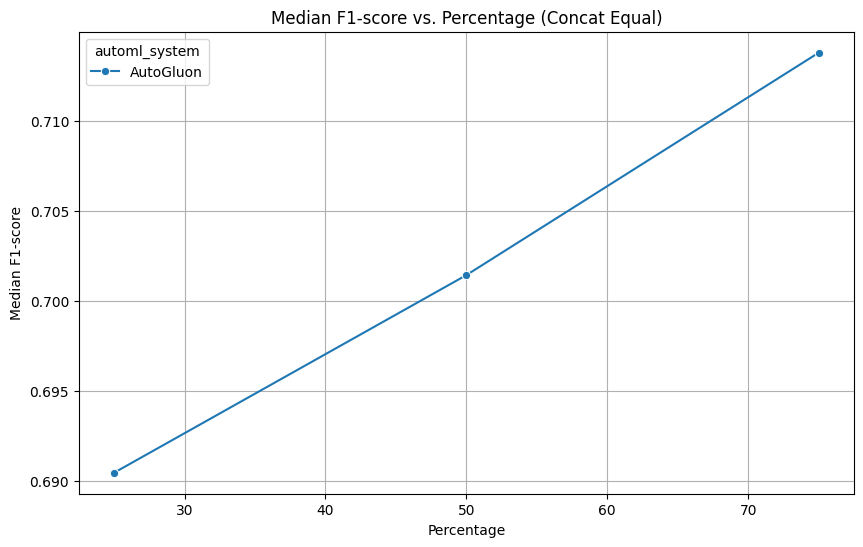

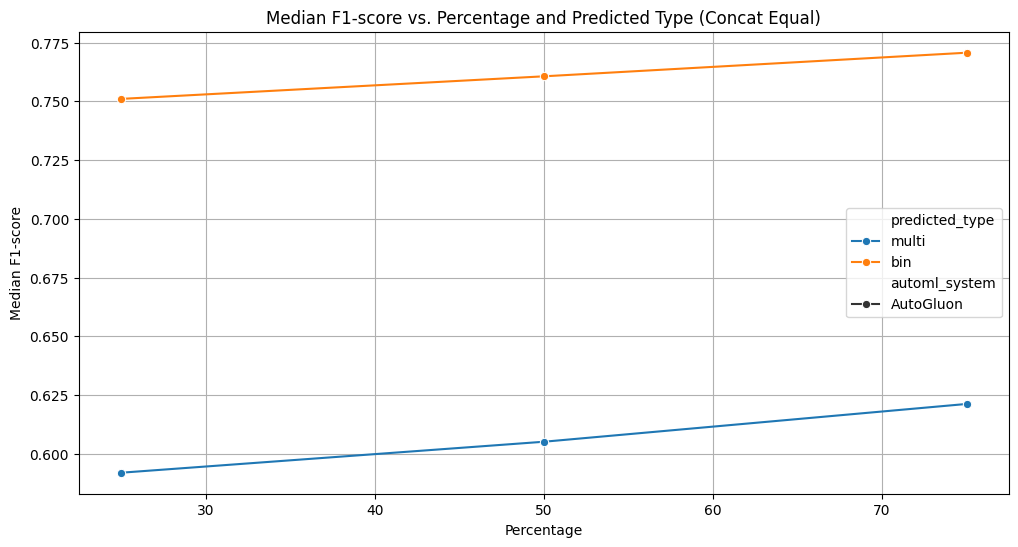

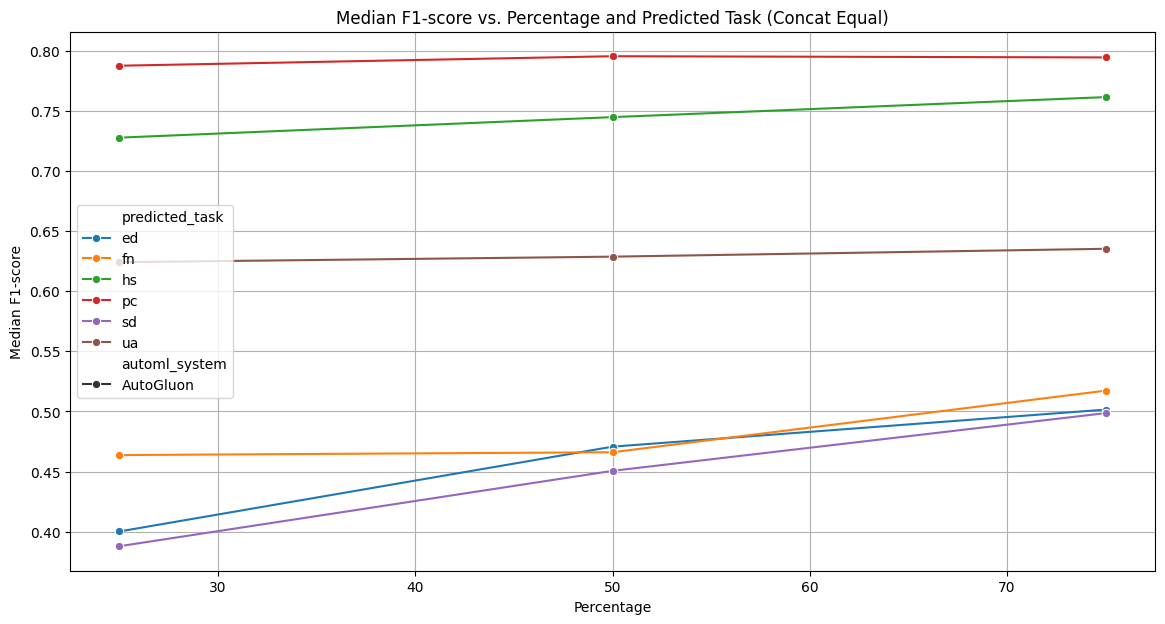

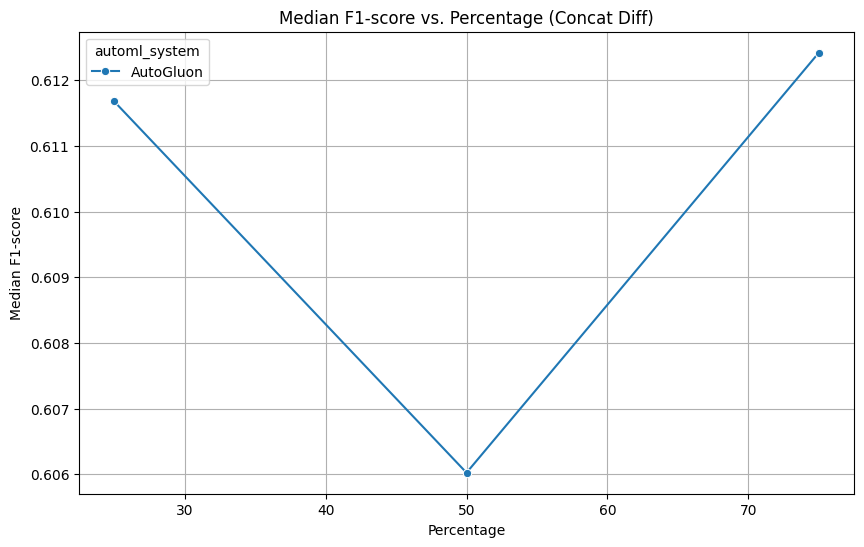

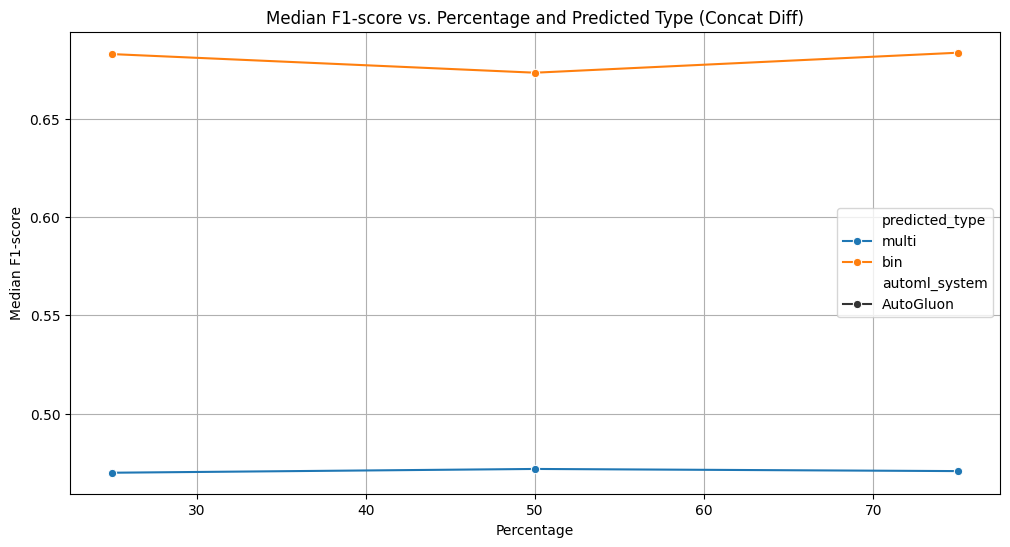

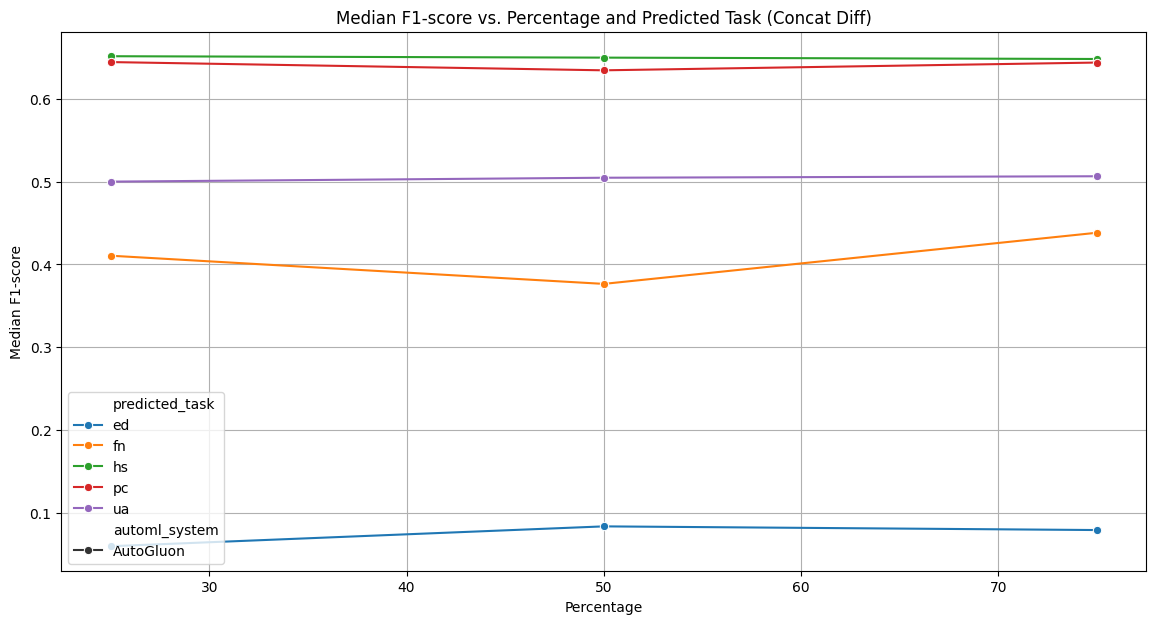

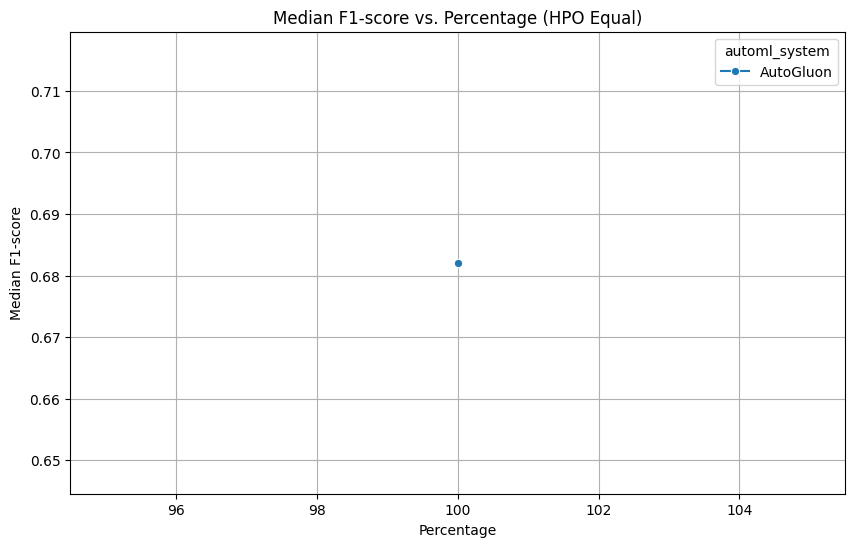

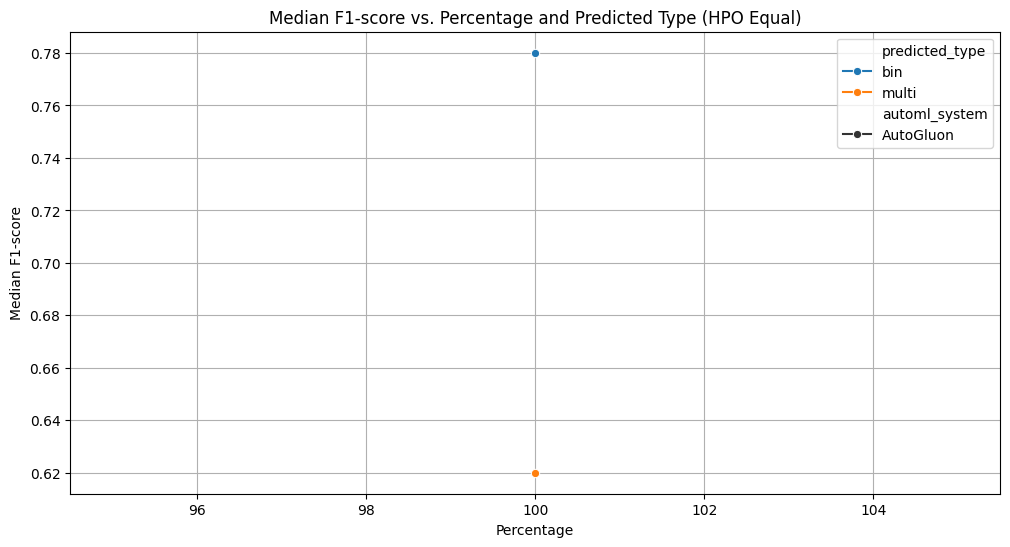

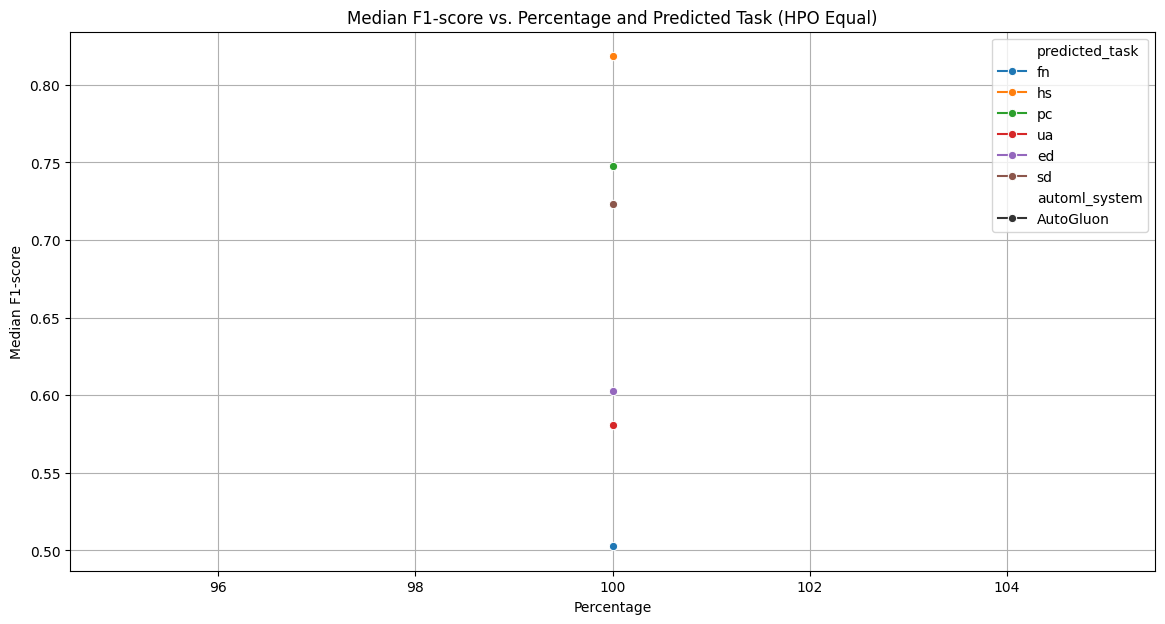

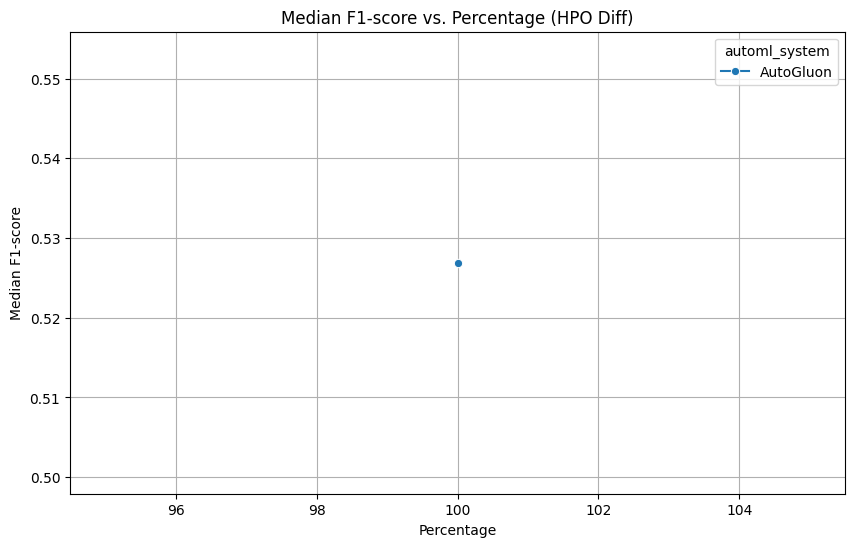

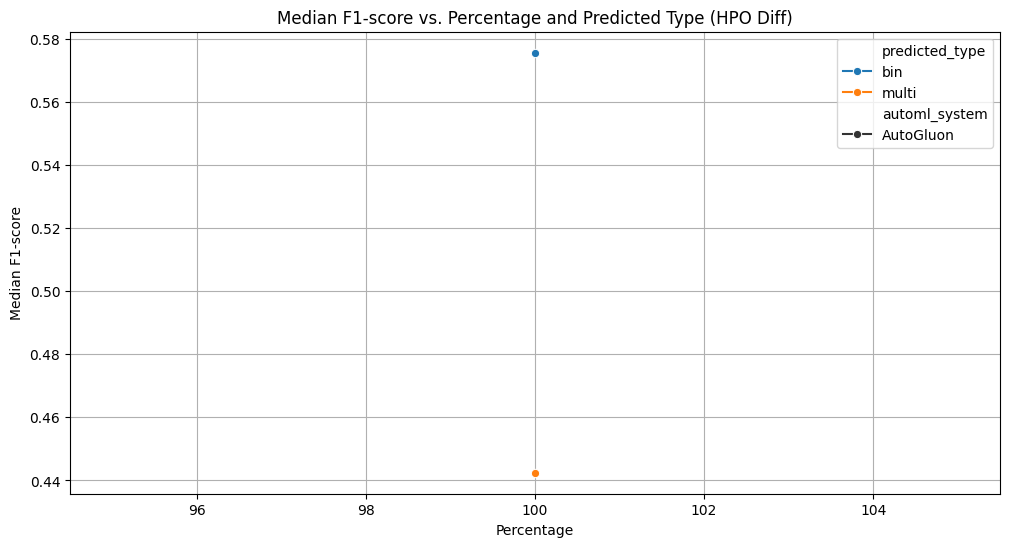

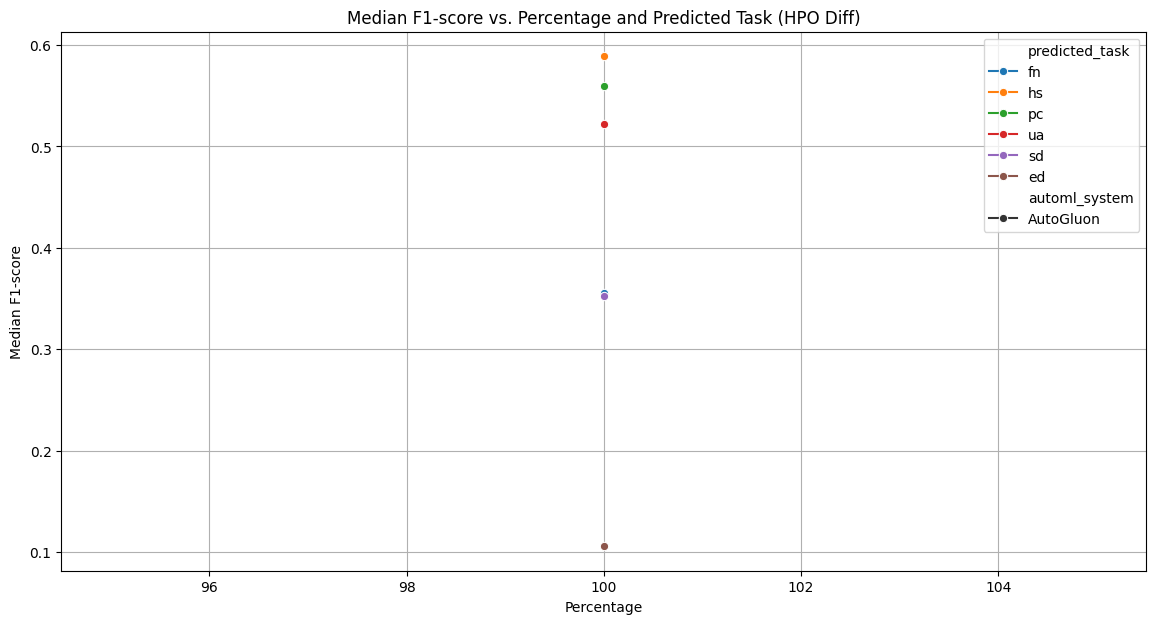


--- Monotonicity Analysis for Concat Equal ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for Concat Diff ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for HPO Equal ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for HPO Diff ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Label Imbalance Ins

/tmp/ipython-input-1745362849.py:257: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")
/tmp/ipython-input-1745362849.py:274: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])
/tmp/ipython-input-1745362849.py:293: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")
/tmp/ipython-input-1745362849.py:310: FutureWarning: The default of observed=Fals

hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.105626
               fn             0.343296
               hs             0.600450
               ua             0.494191
(0.05, 0.1]    hs             0.340656
               pc             0.351837
(0.1, 0.2]     hs             0.574561
               pc             0.459358
               ua             0.538609
(0.2, 0.3]     fn             0.285834
               hs             0.830148
               pc             0.486102
(0.3, 0.5]     fn             0.307323
               hs             0.472141
(0.6, 0.7]     sd             0.333333
(0.7, 0.8]     hs             0.676575
(0.8, 0.9]     fn             0.506944
               hs             0.450348
               sd             0.370667
(0.9, 1.0]     fn             0.445227
               hs             0.656396
               pc             0.738144
               ua             0.502451

In [ ]:
!pip install matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# --- Visualizing Concat Equal ---

# Median F1-score by Percentage for Concat Equal
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None  # Hide error bars for median
)
plt.title("Median F1-score vs. Percentage (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for Concat Equal
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for Concat Equal
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing Concat Diff ---

# Median F1-score by Percentage for Concat Diff
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for Concat Diff
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for Concat Diff
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing HPO Equal ---

# Median F1-score by Percentage for HPO Equal
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for HPO Equal
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for HPO Equal
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing HPO Diff ---

# Median F1-score by Percentage for HPO Diff
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for HPO Diff
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for HPO Diff
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

automl_system = system_map[system]

# Insight regarding monotonicity for Concat Equal
print("\n--- Monotonicity Analysis for Concat Equal ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_concat_equal = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_concat_equal.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for Concat Diff
print("\n--- Monotonicity Analysis for Concat Diff ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_concat_diff = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_concat_diff.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for HPO Equal
print("\n--- Monotonicity Analysis for HPO Equal ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_hpo_equal = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_hpo_equal.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for HPO Diff
print("\n--- Monotonicity Analysis for HPO Diff ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_hpo_diff = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_hpo_diff.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))


# Insight regarding label imbalance for Concat Equal (Percentage 100)
print("\n--- Label Imbalance Insight for Concat Equal (Percentage 100) ---")
concat_equal_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (Concat Equal, 100%):")
print(concat_equal_imbalance_analysis)

concat_equal_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (Concat Equal, 100%):")
print(concat_equal_imbalance_task_analysis)

# Insight regarding label imbalance for Concat Diff (Percentage 100)
print("\n--- Label Imbalance Insight for Concat Diff (Percentage 100) ---")
concat_diff_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (Concat Diff, 100%):")
print(concat_diff_imbalance_analysis)

concat_diff_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (Concat Diff, 100%):")
print(concat_diff_imbalance_task_analysis)


# Insight regarding label imbalance for HPO Equal (Percentage 100)
print("\n--- Label Imbalance Insight for HPO Equal (Percentage 100) ---")
hpo_equal_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (HPO Equal, 100%):")
print(hpo_equal_imbalance_analysis)

hpo_equal_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (HPO Equal, 100%):")
print(hpo_equal_imbalance_task_analysis)

# Insight regarding label imbalance for HPO Diff (Percentage 100)
print("\n--- Label Imbalance Insight for HPO Diff (Percentage 100) ---")
hpo_diff_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (HPO Diff, 100%):")
print(hpo_diff_imbalance_analysis)

hpo_diff_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (HPO Diff, 100%):")
hpo_diff_imbalance_task_analysis
